<a href="https://colab.research.google.com/github/cras-lab/GenAI/blob/main/ToyGPT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


**200개 문장이 가능한 가상 세계 → 100개로 학습 → 나머지 100개로 평가 → 문장 생성**

토큰은 단순히 공백으로 나눈 단어를 사용

필요한 모듈을 임포트 한다.

In [1]:
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

랜덤 시드를 설정한다.

In [ ]:
random.seed(42)         # Python용 Seed : 200개 문장을 무작위로 섞어 학습용 100개와 테스트용 100개로 분할
torch.manual_seed(42)   # PyTorch용 Seed : 신경망 가중치 초기화 및 확률분포에서 다음 토큰 샘플링

## 1. 무작위 200개 문장을 생성

임의로 생성할 문장을 준비한다. 단순히 subjects 와 actions의 조합으로 무작위 문장을 생성한다.

In [3]:
subjects = [
    '민호는', '영희는', '철수는', '지수는', '수진은',
    '준호는', '유나는', '지훈은', '서연은', '하늘은'
]
actions = [
    '책을 읽는다', '물을 마신다', '학교에 간다', '영화를 본다',
    '음악을 듣는다', '숙제를 한다', '빵을 먹는다', '편지를 쓴다',
    '운동을 한다', '산책을 한다', '사진을 찍는다', '커피를 마신다',
    '노래를 부른다', '신문을 읽는다', '춤을 춘다', '버스를 탄다',
    '친구를 만난다', '창문을 연다', '문을 닫는다', '게임을 한다'
]

임의로 문장을 생성해 본다.  
random.shuffle(sentences)는 리스트 sentences의 내부 요소들을 제자리에서 무작위로 섞는다.   
새로운 리스트를 생성 않고 원래의 요소를 제자리에서 바꾼다.

In [4]:
sentences = [s + ' ' + a for s in subjects for a in actions]
random.shuffle(sentences)

전체 중 앞의 100개는 train에, 뒤의 100개는 test에 할당한다.

In [5]:
train = sentences[:100]   # 생성된 문장 앞의 100개는 train으로
test = sentences[100:]    # 생성된 문장 뒤의 100개는 train으로

실제로 어떤 문장들이 생성되었는지 한번 출력해 본다.

In [ ]:
display(pd.DataFrame({'학습 문장': train[:5], '테스트 문장': test[:5]}))

## 2. 단어를 숫자 ID로 바꾸기
`<BOS>`는 시작, `<EOS>`는 끝을 의미하고 입력과 정답을 한 칸씩 어긋나게 만든다.

1) 문장 앞뒤에 BOS, EOS 추가

**민수는 책을 읽는다.**

| 위치 | 0 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|
| 토큰 | `<BOS>` | 민수는 | 책을 | 읽는다 | `<EOS>` |


학습 문장에 등장하는 모든 단어를 중복 없이 수집하고, 정렬한 뒤, <BOS>, <EOS>를 추가해 어휘 목록(Vocabulary)을 만든다.

In [7]:
vocab = ['<BOS>', '<EOS>'] + sorted({w for s in train for w in s.split()})

단어(Word)를 정수 ID로 변환하는 딕셔너리(Dictionary)를 생성한다.

In [8]:
stoi = {word: i for i, word in enumerate(vocab)}

`<BOS>`는 시작, `<EOS>`의 정수 ID를 각각 변수 BOS, EOS에 저장한다.

In [9]:
BOS, EOS = stoi['<BOS>'], stoi['<EOS>']

문장 앞뒤에 BOS, EOS 추가하는 함수를 정의한다.

**민수는 책을 읽는다.**

| 위치 | 0 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|
| 토큰 | `<BOS>` | 민수는 | 책을 | 읽는다 | `<EOS>` |

출력은 두 개를 반환한다.  
tokens[:, :-1]: 모든 문장에서 마지막 EOS를 제외 → 입력 X  
tokens[:, 1:]: 모든 문장에서 첫 번째 BOS를 제외 → 정답 Y  


입력(X)과 정답(Y)을 한 칸씩 이동

| 구분 | 위치 0 | 위치 1 | 위치 2 | 위치 3 |
|---|---|---|---|---|
| 입력 X | `<BOS>` | 민수는 | 책을 | 읽는다 |
| 정답 Y | 민수는 | 책을 | 읽는다 | `<EOS>` |

같은 열에 있는 입력 토큰을 처리한 위치에서 바로 다음 토큰을 정답으로 사용.

학습 과정은 다음과 같다.

| 모델이 볼 수 있는 문맥 | 예측해야 하는 정답 |
|---|---|
| `<BOS>` | 민수는 |
| `<BOS> 민수는` | 책을 |
| `<BOS> 민수는 책을` | 읽는다 |
| `<BOS> 민수는 책을 읽는다` | `<EOS>` |


In [10]:
def make_xy(sentences):
    tokens = torch.tensor([
        [BOS] + [stoi[w] for w in s.split()] + [EOS] for s in sentences
    ])
    return tokens[:, :-1], tokens[:, 1:]




함수를 호출하면,  
X_train은 마지막 EOS를 없앤 문장을, Y_train에는 왼쪽 한칸 Shift한 것이 전달됨

In [11]:
X_train, Y_train = make_xy(train)
X_test, Y_test = make_xy(test)

100개중 제일 앞의 문장에 대해, 이제 숫자로 그 아이디를 출력해 보자.

In [ ]:
V = len(vocab)
example = ['<BOS>'] + train[0].split() + ['<EOS>']
print('어휘 수:', V)
display(pd.DataFrame({'단어': example, 'ID': [stoi[w] for w in example]}))
display(pd.DataFrame({
    '볼 수 있는 문맥': [' '.join(example[:i]) for i in range(1, 5)],
    '예측할 다음 단어': example[1:]
}))

## 3. 작은 Transformer 만들기

## TinyGPT 신경망 전체 구조

<div align="center">

**① 입력 Token ID**

[0, 2, 3, 4]

BOS, 민수는, 책을, 읽는다

↓

**② Token Embedding + Position Embedding**

각 토큰 → 48차원 벡터

↓

**③ Transformer Block 1**

Causal Self-Attention (4 Heads)

Feed Forward Network (48 → 96 → 48)

Residual Connection + Layer Normalization

↓

**④ Transformer Block 2**

Causal Self-Attention (4 Heads)

Feed Forward Network (48 → 96 → 48)

Residual Connection + Layer Normalization

↓

**⑤ Output Linear Layer**

48차원 → V개 단어별 점수 (Logits)

↓

**⑥ Softmax**

각 단어의 확률분포 계산

↓

**⑦ 다음 토큰 선택**

확률분포에서 단어 하나를 샘플링

선택한 단어를 입력에 추가하고 반복

</div>


In [17]:
class TinyGPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(V, 48)
        self.position = nn.Embedding(16, 48)
        self.blocks = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=48, nhead=4, dim_feedforward=96,
                dropout=0.0, batch_first=True
            ) for _ in range(2)
        ])
        self.output = nn.Linear(48, V)

    def forward(self, x):
        length = x.shape[1]
        h = self.embedding(x) + self.position(torch.arange(length))
        # 미래의 정답 단어는 보지 못하게 한다.
        mask = torch.triu(torch.ones(length, length, dtype=torch.bool), diagonal=1)
        for block in self.blocks:
            h = block(h, src_mask=mask)
        return self.output(h)

model = TinyGPT()

## 4. 학습 전: 다음 단어의 확률 보기

@torch.no_grad()는 **PyTorch에서 기울기(Gradient) 계산을 비활성화하는 데코레이터(Decorator)**

신경망 학습이 아니라 **추론(Inference)이나 평가(Evaluation)**를 수행할 때 주로 사용  
def probabilities(ids): 입력된 토큰들(ids)을 바탕으로 다음에 나올 각 단어의 확률을 계산하는 함수를 정의

In [20]:
@torch.no_grad()
def probabilities(ids):
    model.eval()
    logits = model(torch.tensor([ids]))[0, -1]
    return F.softmax(logits, dim=-1)

확률 최상위 6개(top-6)와 실제 선택된 단어를 표시하는 함수를 정의
ef probabilities(ids):
    model.eval()
    logits = model(torch.tensor([ids]))[0, -1]
    return F.softmax(logits, dim=-1)

In [21]:
def show_probs(p, selected=None):
    # 표에는 상위 6개와 실제 선택 단어를 표시.
    ids = p.topk(6).indices.tolist()
    if selected is not None and selected not in ids:
        ids.append(selected)
    table = pd.DataFrame({
        '단어': [vocab[i] for i in ids],
        '확률': [p[i].item() for i in ids],
        '선택': ['← 선택' if i == selected else '' for i in ids]
    })
    display(table.style.bar(subset=['확률'], vmin=0, vmax=1)
            .format({'확률': '{:.2%}'}).hide(axis='index'))

임의의 문장 다음 단어에 대한 학습전의 확률을 표시해 본다.

In [ ]:
probe = [BOS, stoi['민호는'], stoi['책을']]
before = probabilities(probe)
print('문맥: 민수는 책을 → ?')
show_probs(before)

## 5. 학습하고 테스트 손실과 비교하기
Cross-Entropy = 정답 단어의 평균 NLL. 학습 손실만 줄고 테스트 손실이 늘면 과적합  
평균 NLL을 손실함수로 정의한다.

In [23]:
def nll(x, y):
    return F.cross_entropy(model(x).reshape(-1, V), y.reshape(-1))

최적기는 Adam을 선택한다.

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)

나중에 그래프로 그리기 위해, 훈련과 테스트 손실 값을 저장할 리스트를 준비

In [ ]:
train_losses, test_losses = [], []

에폭을 100번 돌며 훈련한다. 동시에 손실 값도 저장한다.

In [ ]:
for epoch in range(100):
    model.train()
    loss = nll(X_train, Y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # 테스트 문장은 평가만 하고, 가중치 갱신에는 사용하지 않는다.
    model.eval()
    with torch.no_grad():
        train_losses.append(nll(X_train, Y_train).item())
        test_losses.append(nll(X_test, Y_test).item())

손실 값 변화를 그래프로 출력해 본다.

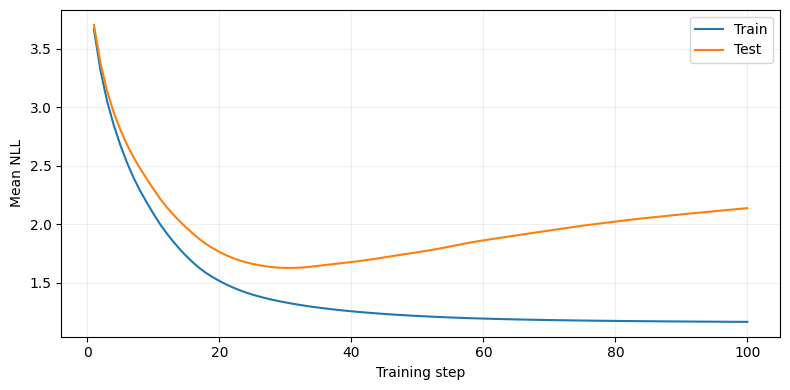

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, 101), train_losses, label='Train')
plt.plot(range(1, 101), test_losses, label='Test')
plt.xlabel('Training step')
plt.ylabel('Mean NLL')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 6. 같은 문맥에서 학습 전후 확률 비교  
훈련을 마쳤으니, 이전 문장의 후속 단어 변화를 보자.  

In [ ]:
after = probabilities(probe)
ids = after.topk(6).indices.tolist()
comparison = pd.DataFrame({
    '단어': [vocab[i] for i in ids],
    '학습 전': before[ids].tolist(),
    '학습 후': after[ids].tolist()
})
print('문맥: 민호는 책을 → ?')
display(comparison.style.bar(subset=['학습 전', '학습 후'], vmin=0, vmax=1)
        .format({'학습 전': '{:.2%}', '학습 후': '{:.2%}'}).hide(axis='index'))

문맥: 민호는 책을 → ?


단어,학습 전,학습 후
읽는다,2.21%,99.09%
닫는다,1.65%,0.13%
본다,4.06%,0.09%
만난다,1.90%,0.08%
탄다,2.21%,0.07%
마신다,1.61%,0.04%


## 7. 실제 확률로 단어를 하나씩 뽑아 문장 만들기
확률 계산 → 하나 추출 → 문맥에 추가 → 반복.  
현재 구현은, top-k나 top-p, best searcn가 아니라, 모든 단어가 후보가 되어 자기의 확률만큼으로 선택된다.

In [ ]:
ids = [BOS]
for step in range(8):
    p = probabilities(ids)
    next_id = torch.multinomial(p, 1).item()  # 전체 어휘의 확률로 추출
    print(f"{step + 1}단계 | 문맥: {' '.join(vocab[i] for i in ids)}")
    print(f"선택: {vocab[next_id]} / 확률: {p[next_id].item():.2%}")
    show_probs(p, selected=next_id)
    if next_id == EOS:
        break
    ids.append(next_id)

text = ' '.join(vocab[i] for i in ids[1:])
print('생성 문장:', text)
if next_id != EOS:
    print('최대 길이에서 중단: 미완성 문장')
elif text in train:
    print('학습했던 문장')
elif text in test:
    print('학습하지 않은 조합: 테스트 문장')
else:
    print('원래 200문장에 없는 결과')